# Ces données ne sont pas concluantes, il s'agit d'un partage informatif et il faudra encore pas mal trafficoter le réseau pour essayer de voir si on peut obtenir un truc correct. => Pooling pour éviter d'avoir autant de pixels 128 x 128 que le réseau peu apprendre par coeur

In [34]:
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import pandas as pd
from pathlib import Path
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix
import json
import time

# Our own package: the same data pipeline and training functions for every model
from museum_guide.data import prepare_subset
from museum_guide.training import count_parameters, evaluate, fit

# Fix the random seed so that every run gives the same results
torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

# Load, split, standardise and batch the style subset (takes about a minute)
style = prepare_subset("style")
print("device:", device, "| classes:", len(style["classes"]), "| train batches:", len(style["train_loader"]))

device: cpu | classes: 27 | train batches: 82


# Deliverable 1: a feed-forward network for artwork classification

## Design choices

| Element | Choice | Why |
|---|---|---|
| Input | 3 x 128 x 128 image, flattened to 49 152 values | default size of the course script (`--size 128`) |
| Hidden layers | 2 layers, 256 then 128 neurons | a simple network, close to the course examples |
| Activation | ReLU | default for hidden layers (TP05) |
| Initialisation | He | recommended with ReLU (TP05, Part D) |
| Output and loss | one logit per class + `CrossEntropyLoss` | standard multi-class recipe (TP05, TP06) |
| Optimiser | Adam, learning rate 1e-3 | usual default of Adam (TP06) |
| Training | 30 epochs, mini-batches of 64 | long enough to see overfitting appear (TP06) |
| Regularisation | none | added and measured in deliverable 2 |

In [23]:
def make_mlp(n_classes, image_shape=(3, 128, 128), hidden_sizes=(256, 128)):
    """Build a feed-forward network (MLP) for colour images, as in TP05 and TP06.

    Args:
        n_classes: number of classes to predict (27 styles or 11 genres).
        image_shape: shape of one input image, (channels, height, width).
        hidden_sizes: number of neurons of each hidden layer.

    Returns:
        An nn.Sequential that maps a batch (B, 3, 128, 128) to (B, n_classes) logits.
    """
    # Turn each image into a vector: (B, 3, 128, 128) -> (B, 49152)
    layers = [nn.Flatten()]
    n_in = image_shape[0] * image_shape[1] * image_shape[2]
    for n_out in hidden_sizes:
        # One hidden layer followed by a ReLU (TP05, Part C)
        layers += [nn.Linear(n_in, n_out), nn.ReLU()]
        n_in = n_out
    # Output layer: one score (logit) per class, no softmax since CrossEntropyLoss applies it
    layers.append(nn.Linear(n_in, n_classes))
    model = nn.Sequential(*layers)

    # He initialisation, recommended for ReLU networks (TP05 Part D, TP06 exercise 21)
    for layer in model.modules():
        if isinstance(layer, nn.Linear):
            nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
            nn.init.zeros_(layer.bias)
    return model


torch.manual_seed(0)
model = make_mlp(n_classes=len(style["classes"])).to(device)
print(model)
print("parameters:", count_parameters(model))

# Check the output shape on one mini-batch
xb, yb = next(iter(style["train_loader"]))
print("output:", tuple(model(xb.to(device)).shape))

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=49152, out_features=256, bias=True)
  (2): ReLU()
  (3): Linear(in_features=256, out_features=128, bias=True)
  (4): ReLU()
  (5): Linear(in_features=128, out_features=27, bias=True)
)
parameters: 12619547
output: (64, 27)


In [24]:
# Start training 

N_EPOCHS = 30
LEARNING_RATE = 1e-3

# Start again from a fresh network, so that the run does not depend on the cells above
torch.manual_seed(0)
style_model = make_mlp(n_classes=len(style["classes"])).to(device)

# The loss and the optimiser chosen together (see the design choices table)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(style_model.parameters(), lr=LEARNING_RATE)

# Train for N_EPOCHS and keep the history of the metrics for the plots
style_history = fit(
    style_model, style["train_loader"], style["val_loader"], loss_fn, optimizer, N_EPOCHS, device=device
)

epoch  1 | train loss 4.482 acc 0.110 | val loss 5.457 acc 0.045 | 3.1 s
epoch  2 | train loss 3.017 acc 0.122 | val loss 3.617 acc 0.047 | 4.6 s
epoch  3 | train loss 2.917 acc 0.156 | val loss 3.636 acc 0.057 | 3.0 s
epoch  4 | train loss 2.864 acc 0.175 | val loss 3.747 acc 0.048 | 2.9 s
epoch  5 | train loss 2.773 acc 0.194 | val loss 3.788 acc 0.047 | 3.2 s
epoch  6 | train loss 2.701 acc 0.216 | val loss 3.965 acc 0.063 | 3.2 s
epoch  7 | train loss 2.681 acc 0.218 | val loss 3.896 acc 0.038 | 3.0 s
epoch  8 | train loss 2.677 acc 0.220 | val loss 4.018 acc 0.046 | 3.2 s
epoch  9 | train loss 2.626 acc 0.243 | val loss 4.222 acc 0.053 | 3.8 s
epoch 10 | train loss 2.605 acc 0.245 | val loss 3.970 acc 0.052 | 3.3 s
epoch 11 | train loss 2.542 acc 0.265 | val loss 4.120 acc 0.064 | 3.1 s
epoch 12 | train loss 2.505 acc 0.276 | val loss 4.295 acc 0.057 | 3.1 s
epoch 13 | train loss 2.601 acc 0.252 | val loss 4.485 acc 0.049 | 3.2 s
epoch 14 | train loss 2.476 acc 0.279 | val loss 4.

KeyboardInterrupt: 

In [ ]:
style_history["val_acc"]

[0.044722719141323794,
 0.046511627906976744,
 0.057245080500894455,
 0.04830053667262969,
 0.04740608228980322,
 0.0626118067978533,
 0.038461538461538464,
 0.04561717352415027,
 0.052772808586762074,
 0.0518783542039356,
 0.06350626118067978,
 0.057245080500894455,
 0.049194991055456175,
 0.04740608228980322,
 0.05635062611806798,
 0.06350626118067978,
 0.05635062611806798,
 0.05635062611806798,
 0.06618962432915922,
 0.061717352415026835,
 0.059033989266547404,
 0.06887298747763863,
 0.05992844364937388,
 0.05992844364937388,
 0.06440071556350627,
 0.06440071556350627,
 0.06797853309481217,
 0.06440071556350627,
 0.06529516994633273,
 0.06529516994633273]

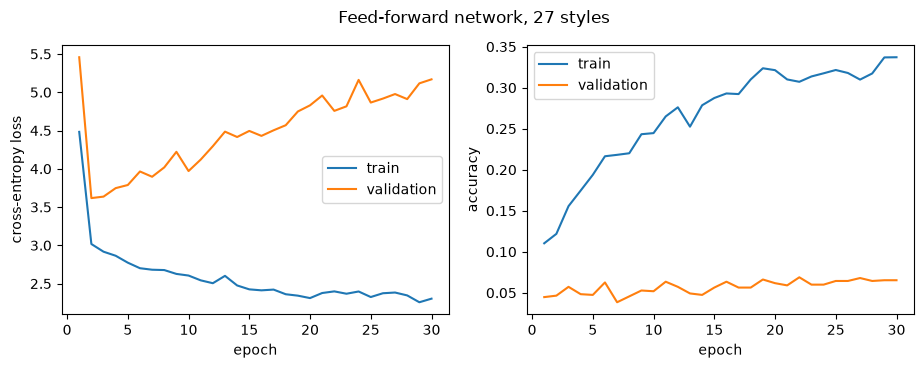

In [ ]:
def plot_history(history, title=""):
    """Plot the loss and accuracy curves of a training run, train versus validation, as in TP06.

    Args:
        history: the dictionary returned by fit.
        title: title of the figure.
    """
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

    # Left: the loss (lower is better)
    axes[0].plot(epochs, history["train_loss"], label="train")
    axes[0].plot(epochs, history["val_loss"], label="validation")
    axes[0].set_xlabel("epoch")
    axes[0].set_ylabel("cross-entropy loss")
    axes[0].legend()

    # Right: the accuracy (higher is better)
    axes[1].plot(epochs, history["train_acc"], label="train")
    axes[1].plot(epochs, history["val_acc"], label="validation")
    axes[1].set_xlabel("epoch")
    axes[1].set_ylabel("accuracy")
    axes[1].legend()

    fig.suptitle(title)
    plt.show()


plot_history(style_history, "Feed-forward network, 27 styles")

## Try 2: a simpler network (one hidden layer of 128 neurons)

The first network (256 then 128 neurons, 12.6 M weights) learnt the training images by heart:
the validation loss rose from epoch 2 on, and the validation accuracy stayed close to chance (about 4 %).

| Element | Try 1 | Try 2 |
|---|---|---|
| Hidden layers | 256 then 128 neurons | **1 layer of 128 neurons** |
| Weights | 12.6 M | **6.3 M** |
| Learning rate | 1e-3 | 1e-3 |
| Everything else | ReLU, He, Adam, 30 epochs | unchanged |

parameters: 6295067
epoch  1 | train loss 18.561 acc 0.165 | val loss 24.588 acc 0.068 | 1.8 s
epoch  2 | train loss 14.189 acc 0.187 | val loss 23.168 acc 0.056 | 1.8 s
epoch  3 | train loss 11.673 acc 0.256 | val loss 21.574 acc 0.070 | 1.9 s
epoch  4 | train loss 11.739 acc 0.270 | val loss 23.558 acc 0.047 | 1.9 s
epoch  5 | train loss 10.171 acc 0.307 | val loss 22.992 acc 0.064 | 2.0 s
epoch  6 | train loss 6.928 acc 0.375 | val loss 22.028 acc 0.078 | 2.0 s
epoch  7 | train loss 7.118 acc 0.383 | val loss 22.023 acc 0.074 | 2.1 s
epoch  8 | train loss 6.272 acc 0.386 | val loss 22.820 acc 0.060 | 2.2 s
epoch  9 | train loss 9.526 acc 0.374 | val loss 27.771 acc 0.067 | 2.5 s
epoch 10 | train loss 5.532 acc 0.440 | val loss 23.745 acc 0.063 | 2.4 s
epoch 11 | train loss 5.002 acc 0.469 | val loss 23.215 acc 0.081 | 2.5 s
epoch 12 | train loss 8.265 acc 0.434 | val loss 27.935 acc 0.062 | 2.4 s
epoch 13 | train loss 4.184 acc 0.486 | val loss 23.264 acc 0.057 | 2.3 s
epoch 14 | tr

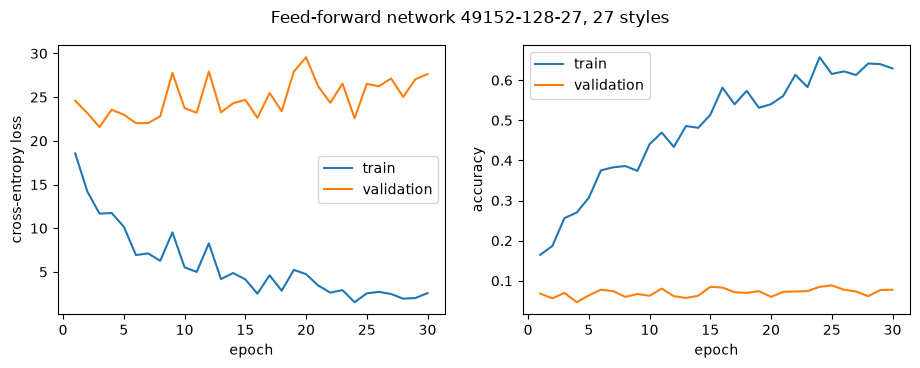

In [ ]:
# Second try: a simpler network with one hidden layer of 128 neurons (option A),
# because the 256-128 network learnt the training images by heart
torch.manual_seed(0)
style_model_a = make_mlp(n_classes=len(style["classes"]), hidden_sizes=(128,)).to(device)
print("parameters:", count_parameters(style_model_a))

# Same loss and same optimiser settings as the first try, only the network changes
optimizer = torch.optim.Adam(style_model_a.parameters(), lr=LEARNING_RATE)
style_history_a = fit(
    style_model_a, style["train_loader"], style["val_loader"], loss_fn, optimizer, N_EPOCHS, device=device
)
plot_history(style_history_a, "Feed-forward network 49152-128-27, 27 styles")

## Try 3: a basic network (one hidden layer of 32 neurons)

Try 2 still learnt by heart, and its loss reached 20 to 30 with jumps on the training curve:
the network gives very confident wrong answers. We first test whether a much smaller network is enough.

| Element | Try 2 | Try 3 |
|---|---|---|
| Hidden layers | 1 layer of 128 neurons | **1 layer of 32 neurons** |
| Weights | 6.3 M | **1.6 M** |
| Learning rate | 1e-3 | 1e-3 |
| Everything else | ReLU, He, Adam, 30 epochs | unchanged |

parameters: 1573787
epoch  1 | train loss 8.211 acc 0.123 | val loss 10.083 acc 0.065 | 0.8 s
epoch  2 | train loss 7.412 acc 0.136 | val loss 10.560 acc 0.040 | 0.8 s
epoch  3 | train loss 6.751 acc 0.161 | val loss 10.486 acc 0.055 | 0.8 s
epoch  4 | train loss 6.643 acc 0.183 | val loss 11.371 acc 0.057 | 0.8 s
epoch  5 | train loss 5.657 acc 0.214 | val loss 10.969 acc 0.063 | 0.7 s
epoch  6 | train loss 5.494 acc 0.234 | val loss 11.038 acc 0.058 | 0.7 s
epoch  7 | train loss 5.100 acc 0.245 | val loss 10.855 acc 0.054 | 0.9 s
epoch  8 | train loss 4.075 acc 0.284 | val loss 10.821 acc 0.069 | 0.7 s
epoch  9 | train loss 3.754 acc 0.302 | val loss 10.707 acc 0.055 | 0.7 s
epoch 10 | train loss 4.028 acc 0.306 | val loss 11.251 acc 0.063 | 0.7 s
epoch 11 | train loss 3.692 acc 0.310 | val loss 10.981 acc 0.051 | 0.7 s
epoch 12 | train loss 3.209 acc 0.342 | val loss 10.417 acc 0.059 | 0.7 s
epoch 13 | train loss 3.882 acc 0.330 | val loss 11.838 acc 0.048 | 0.7 s
epoch 14 | train l

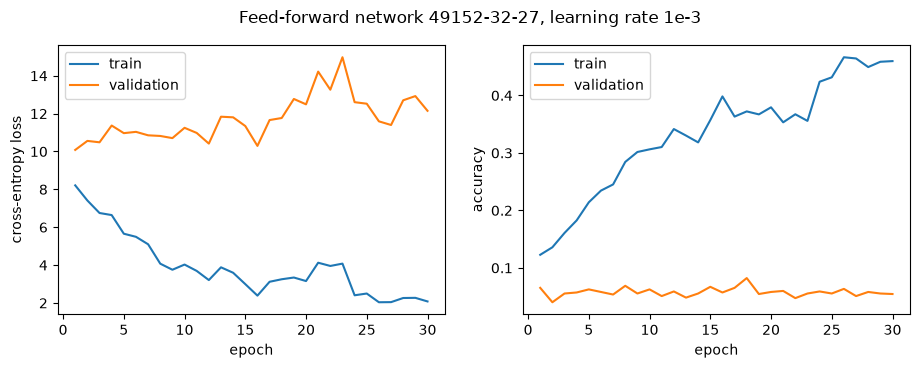

In [ ]:
# Third try: a basic network with one hidden layer of 32 neurons.
# Only the size changes: the learning rate stays at 1e-3.
torch.manual_seed(0)
style_model_c = make_mlp(n_classes=len(style["classes"]), hidden_sizes=(32,)).to(device)
print("parameters:", count_parameters(style_model_c))

optimizer = torch.optim.Adam(style_model_c.parameters(), lr=1e-3)
style_history_c = fit(
    style_model_c, style["train_loader"], style["val_loader"], loss_fn, optimizer, N_EPOCHS, device=device
)
plot_history(style_history_c, "Feed-forward network 49152-32-27, learning rate 1e-3")

## Tries 4 to 6: the same three networks with a learning rate 10 times smaller

Tries 1 to 3 changed the size of the network and none of them generalised: the validation accuracy
stayed close to chance (about 4 %), and the losses were very high with jumps on the training curves.
Hypothesis: the steps of the optimiser are too large. Adam moves each weight by about the learning rate
at every step, and each neuron of the first layer has 49 152 inputs: all these small moves add up to
large jumps. We train the same three networks again with a learning rate of 1e-4 instead of 1e-3,
and change nothing else.

In [ ]:
def train_style_mlp(hidden_sizes, learning_rate, n_epochs=N_EPOCHS):
    """Build a fresh feed-forward network for the styles and train it with Adam.

    Args:
        hidden_sizes: number of neurons of each hidden layer, for example (128,).
        learning_rate: learning rate of Adam.
        n_epochs: number of epochs.

    Returns:
        (model, history): the trained network and the history returned by fit.
    """
    # Same seed for every try: same initial weights and same order of the mini-batches
    torch.manual_seed(0)
    model = make_mlp(n_classes=len(style["classes"]), hidden_sizes=hidden_sizes).to(device)
    print("parameters:", count_parameters(model))

    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history = fit(
        model, style["train_loader"], style["val_loader"], loss_fn, optimizer, n_epochs, device=device
    )
    return model, history

### Try 4: two hidden layers (256 then 128 neurons), learning rate 1e-4

| Element | Try 1 | Try 4 |
|---|---|---|
| Hidden layers | 256 then 128 neurons | 256 then 128 neurons |
| Weights | 12.6 M | 12.6 M |
| Learning rate | 1e-3 | **1e-4** |
| Everything else | ReLU, He, Adam, 30 epochs | unchanged |

parameters: 12619547
epoch  1 | train loss 3.053 acc 0.195 | val loss 3.942 acc 0.080 | 3.6 s
epoch  2 | train loss 2.536 acc 0.337 | val loss 3.844 acc 0.097 | 3.6 s
epoch  3 | train loss 2.013 acc 0.453 | val loss 3.936 acc 0.088 | 3.4 s
epoch  4 | train loss 1.738 acc 0.525 | val loss 4.068 acc 0.064 | 3.4 s
epoch  5 | train loss 1.503 acc 0.606 | val loss 4.217 acc 0.080 | 3.6 s
epoch  6 | train loss 1.227 acc 0.681 | val loss 4.360 acc 0.087 | 3.6 s
epoch  7 | train loss 1.236 acc 0.685 | val loss 4.646 acc 0.097 | 3.9 s
epoch  8 | train loss 0.904 acc 0.763 | val loss 4.581 acc 0.101 | 3.6 s
epoch  9 | train loss 0.676 acc 0.831 | val loss 4.666 acc 0.104 | 3.9 s
epoch 10 | train loss 0.700 acc 0.822 | val loss 4.957 acc 0.085 | 3.9 s
epoch 11 | train loss 0.516 acc 0.879 | val loss 4.909 acc 0.102 | 4.1 s
epoch 12 | train loss 0.520 acc 0.875 | val loss 5.057 acc 0.089 | 3.8 s
epoch 13 | train loss 0.517 acc 0.868 | val loss 5.271 acc 0.094 | 3.7 s
epoch 14 | train loss 0.449 ac

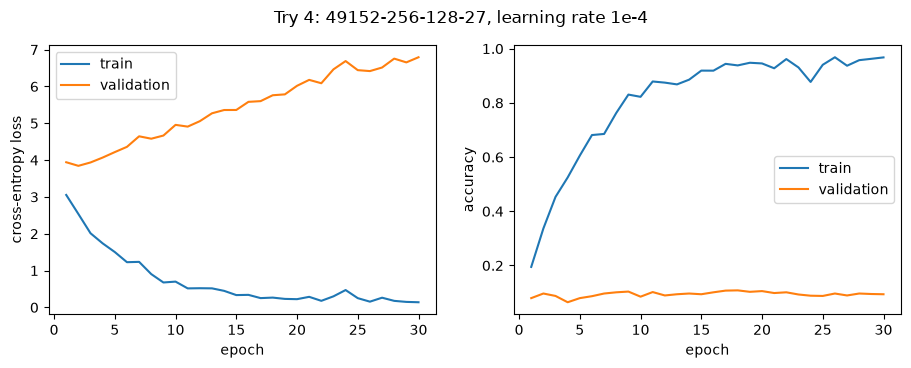

In [ ]:
# Try 4: the network of try 1 with a learning rate 10 times smaller
style_model_4, style_history_4 = train_style_mlp(hidden_sizes=(256, 128), learning_rate=1e-4)
plot_history(style_history_4, "Try 4: 49152-256-128-27, learning rate 1e-4")

### Try 5: one hidden layer of 128 neurons, learning rate 1e-4

| Element | Try 2 | Try 5 |
|---|---|---|
| Hidden layers | 1 layer of 128 neurons | 1 layer of 128 neurons |
| Weights | 6.3 M | 6.3 M |
| Learning rate | 1e-3 | **1e-4** |
| Everything else | ReLU, He, Adam, 30 epochs | unchanged |

parameters: 6295067
epoch  1 | train loss 3.371 acc 0.195 | val loss 4.369 acc 0.073 | 1.5 s
epoch  2 | train loss 2.869 acc 0.298 | val loss 4.491 acc 0.079 | 1.5 s
epoch  3 | train loss 2.146 acc 0.450 | val loss 4.287 acc 0.082 | 1.5 s
epoch  4 | train loss 1.864 acc 0.514 | val loss 4.487 acc 0.079 | 1.6 s
epoch  5 | train loss 1.873 acc 0.567 | val loss 4.954 acc 0.081 | 1.6 s
epoch  6 | train loss 1.356 acc 0.657 | val loss 4.664 acc 0.089 | 1.6 s
epoch  7 | train loss 1.260 acc 0.686 | val loss 4.798 acc 0.092 | 1.6 s
epoch  8 | train loss 0.963 acc 0.768 | val loss 4.870 acc 0.084 | 1.7 s
epoch  9 | train loss 0.844 acc 0.790 | val loss 4.893 acc 0.085 | 2.1 s
epoch 10 | train loss 0.787 acc 0.812 | val loss 5.172 acc 0.085 | 3.7 s
epoch 11 | train loss 0.699 acc 0.832 | val loss 5.179 acc 0.088 | 3.8 s
epoch 12 | train loss 0.868 acc 0.790 | val loss 5.718 acc 0.087 | 3.8 s
epoch 13 | train loss 0.454 acc 0.890 | val loss 5.340 acc 0.097 | 3.7 s
epoch 14 | train loss 0.559 acc

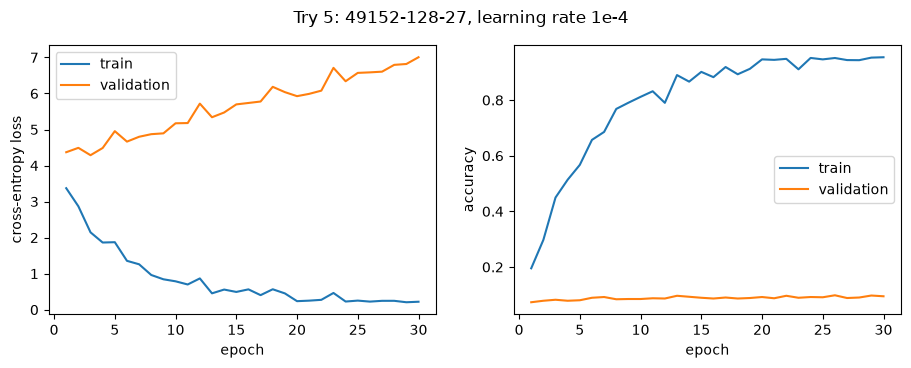

In [ ]:
# Try 5: the network of try 2 with a learning rate 10 times smaller
style_model_5, style_history_5 = train_style_mlp(hidden_sizes=(128,), learning_rate=1e-4)
plot_history(style_history_5, "Try 5: 49152-128-27, learning rate 1e-4")

### Try 6: one hidden layer of 32 neurons, learning rate 1e-4

| Element | Try 3 | Try 6 |
|---|---|---|
| Hidden layers | 1 layer of 32 neurons | 1 layer of 32 neurons |
| Weights | 1.6 M | 1.6 M |
| Learning rate | 1e-3 | **1e-4** |
| Everything else | ReLU, He, Adam, 30 epochs | unchanged |

parameters: 1573787
epoch  1 | train loss 3.277 acc 0.129 | val loss 3.744 acc 0.079 | 1.0 s
epoch  2 | train loss 3.143 acc 0.174 | val loss 3.909 acc 0.067 | 0.8 s
epoch  3 | train loss 2.860 acc 0.211 | val loss 3.911 acc 0.060 | 0.7 s
epoch  4 | train loss 2.652 acc 0.252 | val loss 3.933 acc 0.071 | 0.7 s
epoch  5 | train loss 2.547 acc 0.308 | val loss 4.060 acc 0.077 | 0.7 s
epoch  6 | train loss 2.165 acc 0.396 | val loss 3.891 acc 0.072 | 0.6 s
epoch  7 | train loss 1.997 acc 0.437 | val loss 3.892 acc 0.081 | 0.7 s
epoch  8 | train loss 1.995 acc 0.458 | val loss 4.094 acc 0.058 | 0.6 s
epoch  9 | train loss 1.881 acc 0.489 | val loss 4.188 acc 0.077 | 0.7 s
epoch 10 | train loss 1.674 acc 0.544 | val loss 4.176 acc 0.077 | 0.7 s
epoch 11 | train loss 1.724 acc 0.543 | val loss 4.338 acc 0.070 | 0.6 s
epoch 12 | train loss 1.387 acc 0.639 | val loss 4.188 acc 0.082 | 0.7 s
epoch 13 | train loss 1.524 acc 0.596 | val loss 4.465 acc 0.070 | 0.7 s
epoch 14 | train loss 1.369 acc

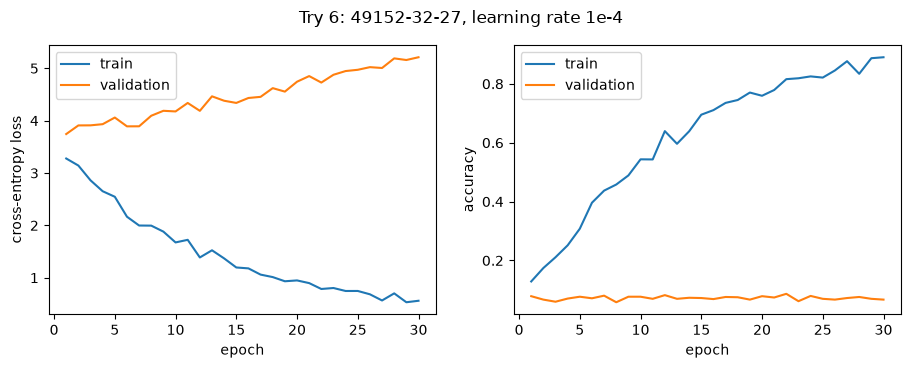

In [ ]:
# Try 6: the network of try 3 with a learning rate 10 times smaller
style_model_6, style_history_6 = train_style_mlp(hidden_sizes=(32,), learning_rate=1e-4)
plot_history(style_history_6, "Try 6: 49152-32-27, learning rate 1e-4")


## Tries 7 and 8: average pooling before the dense network

All the previous networks flatten the 49 152 pixel values: too many inputs for about 5 200
training images, and the dense layer does not know which pixels are neighbours (course S07, slide 4).
We keep the network of try 4 (256 then 128 neurons, learning rate 1e-4) and add one layer in front of it:
`nn.AvgPool2d(k)` replaces each block of k x k pixels by its mean (course S07, slide 12).
It has no weight to learn, so the model stays a dense network, with k ** 2 times fewer inputs.

| Element | Try 4 | Try 7 | Try 8 |
|---|---|---|---|
| Pooling before the network | none | **4 x 4 average** | **8 x 8 average** |
| Image seen by the dense layers | 128 x 128 | 32 x 32 | 16 x 16 |
| Inputs | 49 152 | 3 072 | 768 |
| Everything else | 256-128, ReLU, He, Adam lr 1e-4, 30 epochs | unchanged | unchanged |

In [ ]:
def make_pooled_mlp(n_classes, pool_size, hidden_sizes=(256, 128)):
    """Build an average pooling layer followed by the feed-forward network of make_mlp.

    Args:
        n_classes: number of classes to predict (27 styles or 11 genres).
        pool_size: each block of pool_size x pool_size pixels is replaced by its mean.
        hidden_sizes: number of neurons of each hidden layer of the dense network.

    Returns:
        An nn.Sequential that maps a batch (B, 3, 128, 128) to (B, n_classes) logits.
    """
    # Size of the image after pooling, for example 128 // 4 = 32
    pooled_side = 128 // pool_size
    return nn.Sequential(
        # Summarise each block of pixels by its mean (course S07, slide 12): no weight to learn
        nn.AvgPool2d(pool_size),
        # The unchanged dense network, built for the smaller pooled image
        make_mlp(n_classes, image_shape=(3, pooled_side, pooled_side), hidden_sizes=hidden_sizes),
    )


def train_style_pooled_mlp(pool_size, learning_rate=1e-4, hidden_sizes=(256, 128), n_epochs=N_EPOCHS):
    """Build a fresh pooled network for the styles and train it with Adam, like train_style_mlp.

    Returns:
        (model, history): the trained network and the history returned by fit.
    """
    # Same seed as the other tries: same initial weights and same order of the mini-batches
    torch.manual_seed(0)
    model = make_pooled_mlp(len(style["classes"]), pool_size, hidden_sizes).to(device)
    print("parameters:", count_parameters(model))

    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate)
    history = fit(
        model, style["train_loader"], style["val_loader"], loss_fn, optimizer, n_epochs, device=device
    )
    return model, history


# Quick check of the number of weights, before any training
for pool in [4, 8]:
    print(f"pool {pool}: {count_parameters(make_pooled_mlp(len(style['classes']), pool)):,} parameters")

pool 4: 823,067 parameters
pool 8: 233,243 parameters


parameters: 823067
epoch  1 | train loss 3.026 acc 0.146 | val loss 3.227 acc 0.120 | 0.5 s
epoch  2 | train loss 2.815 acc 0.196 | val loss 3.169 acc 0.102 | 0.5 s
epoch  3 | train loss 2.636 acc 0.265 | val loss 3.143 acc 0.114 | 0.5 s
epoch  4 | train loss 2.511 acc 0.304 | val loss 3.160 acc 0.116 | 0.5 s
epoch  5 | train loss 2.368 acc 0.356 | val loss 3.138 acc 0.118 | 0.5 s
epoch  6 | train loss 2.241 acc 0.405 | val loss 3.135 acc 0.126 | 0.5 s
epoch  7 | train loss 2.147 acc 0.444 | val loss 3.141 acc 0.127 | 0.5 s
epoch  8 | train loss 2.028 acc 0.480 | val loss 3.148 acc 0.131 | 1.5 s
epoch  9 | train loss 1.914 acc 0.525 | val loss 3.168 acc 0.131 | 0.8 s
epoch 10 | train loss 1.817 acc 0.557 | val loss 3.163 acc 0.127 | 0.6 s
epoch 11 | train loss 1.746 acc 0.578 | val loss 3.208 acc 0.130 | 0.6 s
epoch 12 | train loss 1.656 acc 0.610 | val loss 3.218 acc 0.136 | 0.5 s
epoch 13 | train loss 1.585 acc 0.632 | val loss 3.255 acc 0.127 | 0.5 s
epoch 14 | train loss 1.499 acc 

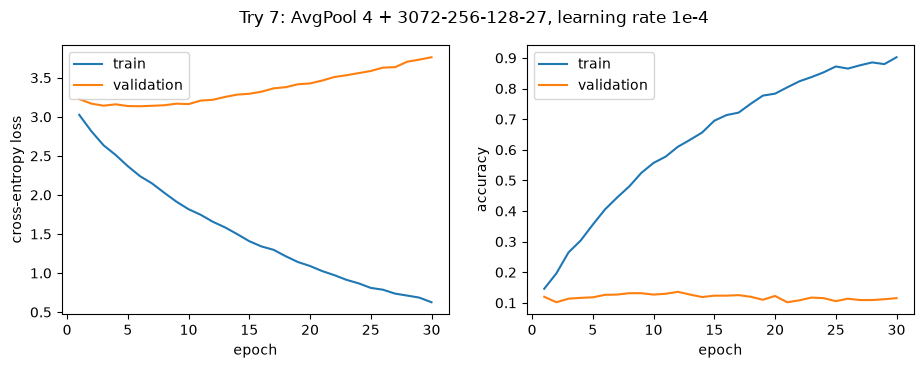

In [ ]:
# Try 7: 4 x 4 average pooling (the network sees a 32 x 32 image), then the network of try 4
style_model_7, style_history_7 = train_style_pooled_mlp(pool_size=4)
plot_history(style_history_7, "Try 7: AvgPool 4 + 3072-256-128-27, learning rate 1e-4")

parameters: 233243
epoch  1 | train loss 3.192 acc 0.086 | val loss 3.278 acc 0.072 | 0.5 s
epoch  2 | train loss 3.057 acc 0.119 | val loss 3.218 acc 0.067 | 0.4 s
epoch  3 | train loss 2.969 acc 0.135 | val loss 3.185 acc 0.084 | 0.4 s
epoch  4 | train loss 2.902 acc 0.155 | val loss 3.169 acc 0.091 | 0.4 s
epoch  5 | train loss 2.832 acc 0.183 | val loss 3.149 acc 0.092 | 0.5 s
epoch  6 | train loss 2.774 acc 0.205 | val loss 3.144 acc 0.095 | 0.4 s
epoch  7 | train loss 2.723 acc 0.222 | val loss 3.141 acc 0.097 | 0.4 s
epoch  8 | train loss 2.671 acc 0.239 | val loss 3.136 acc 0.106 | 0.4 s
epoch  9 | train loss 2.621 acc 0.248 | val loss 3.131 acc 0.120 | 0.4 s
epoch 10 | train loss 2.575 acc 0.271 | val loss 3.128 acc 0.121 | 0.4 s
epoch 11 | train loss 2.534 acc 0.287 | val loss 3.127 acc 0.110 | 0.4 s
epoch 12 | train loss 2.492 acc 0.308 | val loss 3.130 acc 0.116 | 0.4 s
epoch 13 | train loss 2.446 acc 0.319 | val loss 3.126 acc 0.112 | 0.4 s
epoch 14 | train loss 2.409 acc 

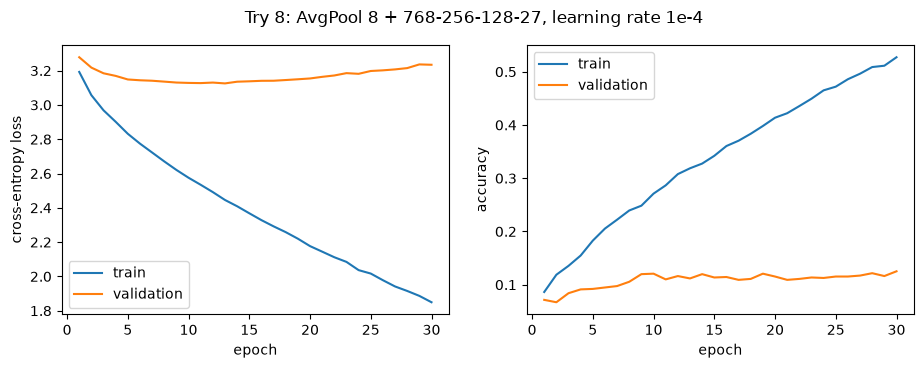

In [ ]:
# Try 8: 8 x 8 average pooling (the network sees a 16 x 16 image), then the network of try 4
style_model_8, style_history_8 = train_style_pooled_mlp(pool_size=8)
plot_history(style_history_8, "Try 8: AvgPool 8 + 768-256-128-27, learning rate 1e-4")

## Summary of the eight tries

For each try: the epoch with the best validation accuracy, and that accuracy.
Chance level with 27 styles: about 0.04.

In [ ]:
# One line per try: (number, hidden layers, learning rate, pooling, history returned by fit).
# The history variables are the ones created in the cells above.
tries = [
    (1, "2 layers: 256, 128", 1e-3, "none", style_history),
    (2, "1 layer: 128", 1e-3, "none", style_history_a),
    (3, "1 layer: 32", 1e-3, "none", style_history_c),
    (4, "2 layers: 256, 128", 1e-4, "none", style_history_4),
    (5, "1 layer: 128", 1e-4, "none", style_history_5),
    (6, "1 layer: 32", 1e-4, "none", style_history_6),
    (7, "2 layers: 256, 128", 1e-4, "4 x 4 average", style_history_7),
    (8, "2 layers: 256, 128", 1e-4, "8 x 8 average", style_history_8),
]

rows = []
for number, layers, learning_rate, pooling, history in tries:
    # Best validation accuracy over the 30 epochs, and the epoch where it was reached (counted from 1)
    best_acc = max(history["val_acc"])
    best_epoch = history["val_acc"].index(best_acc) + 1
    rows.append({
        "try": number,
        "hidden layers": layers,
        "learning rate": learning_rate,
        "pooling": pooling,
        "best epoch": best_epoch,
        "best val accuracy": round(best_acc, 3),
    })

# One row per try, indexed by the try number
style_summary = pd.DataFrame(rows).set_index("try")
style_summary.sort_values("best val accuracy", ascending=False)

,hidden layers,learning rate,pooling,best epoch,best val accuracy
try,,,,,
7,"2 layers: 256, 128",0.0001,4 x 4 average,12,0.136
8,"2 layers: 256, 128",0.0001,8 x 8 average,30,0.125
4,"2 layers: 256, 128",0.0001,none,18,0.108
5,1 layer: 128,0.0001,none,26,0.098
2,1 layer: 128,0.0010,none,25,0.089
6,1 layer: 32,0.0001,none,22,0.087
3,1 layer: 32,0.0010,none,18,0.082
1,"2 layers: 256, 128",0.0010,none,22,0.069


## Final network: try 7 trained for 12 epochs

Try 7 (4 x 4 average pooling, then 256-128, learning rate 1e-4) has the best validation accuracy
of the eight tries, reached at epoch 12. The number of epochs is a setting chosen on validation,
like the learning rate: we train the same network again for 12 epochs instead of 30.
With the same seed, these 12 epochs are the same as the first 12 epochs of try 7.

parameters: 823067
epoch  1 | train loss 3.026 acc 0.146 | val loss 3.227 acc 0.120 | 0.5 s
epoch  2 | train loss 2.815 acc 0.196 | val loss 3.169 acc 0.102 | 0.6 s
epoch  3 | train loss 2.636 acc 0.265 | val loss 3.143 acc 0.114 | 0.7 s
epoch  4 | train loss 2.511 acc 0.304 | val loss 3.160 acc 0.116 | 0.5 s
epoch  5 | train loss 2.368 acc 0.356 | val loss 3.138 acc 0.118 | 0.6 s
epoch  6 | train loss 2.241 acc 0.405 | val loss 3.135 acc 0.126 | 0.6 s
epoch  7 | train loss 2.147 acc 0.444 | val loss 3.141 acc 0.127 | 0.6 s
epoch  8 | train loss 2.028 acc 0.480 | val loss 3.148 acc 0.131 | 1.9 s
epoch  9 | train loss 1.914 acc 0.525 | val loss 3.168 acc 0.131 | 2.0 s
epoch 10 | train loss 1.817 acc 0.557 | val loss 3.163 acc 0.127 | 1.9 s
epoch 11 | train loss 1.746 acc 0.578 | val loss 3.208 acc 0.130 | 1.8 s
epoch 12 | train loss 1.656 acc 0.610 | val loss 3.218 acc 0.136 | 0.6 s
validation accuracy at epoch 12: 0.136 (try 7 at the same epoch: 0.136)


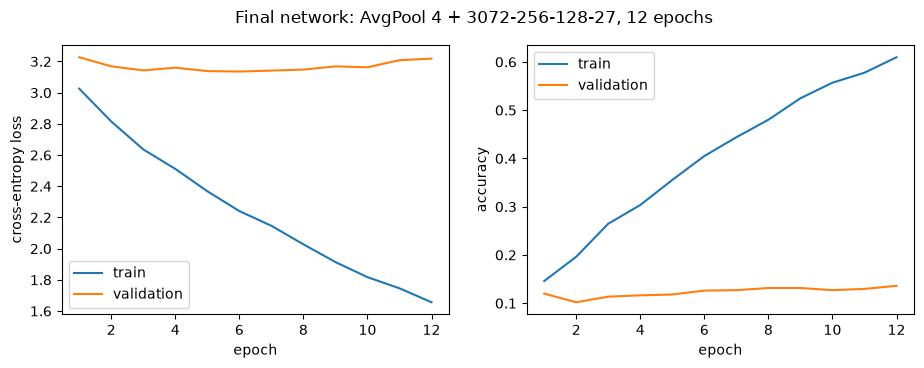

In [27]:
FINAL_EPOCHS = 12  # epoch of the best validation accuracy of try 7 (see the summary table)

# Same settings as try 7, only the number of epochs changes
final_model, final_history = train_style_pooled_mlp(pool_size=4, n_epochs=FINAL_EPOCHS)

# Check: same seed, so the last validation accuracy must equal the one of try 7 at epoch 12
print(
    f"validation accuracy at epoch {FINAL_EPOCHS}: {final_history['val_acc'][-1]:.3f} "
    f"(try 7 at the same epoch: {style_history_7['val_acc'][FINAL_EPOCHS - 1]:.3f})"
)
plot_history(final_history, f"Final network: AvgPool 4 + 3072-256-128-27, {FINAL_EPOCHS} epochs")

## Final evaluation on the test set (once)

The final network is now measured once on the test images, never used for training
nor for choosing the model or the number of epochs.

In [31]:
# Folder of the team's figures (created if it does not exist yet)
FIG_DIR = Path("..") / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# The final network, measured ONCE on the test images
test_loss, test_acc = evaluate(final_model, style["test_loader"], loss_fn, device=device)
n_classes = len(style["classes"])
print(
    f"TEST accuracy = {test_acc:.3f} "
    f"| validation accuracy {final_history['val_acc'][-1]:.3f} | chance {1 / n_classes:.3f}"
)

# Predicted class of every test image (the test loader is not shuffled, so the order is kept)
final_model.eval()
with torch.no_grad():
    y_pred = torch.cat(
        [final_model(xb.to(device)).argmax(dim=1).cpu() for xb, _ in style["test_loader"]]
    ).numpy()

# True class of the same test images, in the same order
y_true = style["y"][torch.as_tensor(style["test_idx"])].numpy()

TEST accuracy = 0.114 | validation accuracy 0.136 | chance 0.037


## Confusion matrix

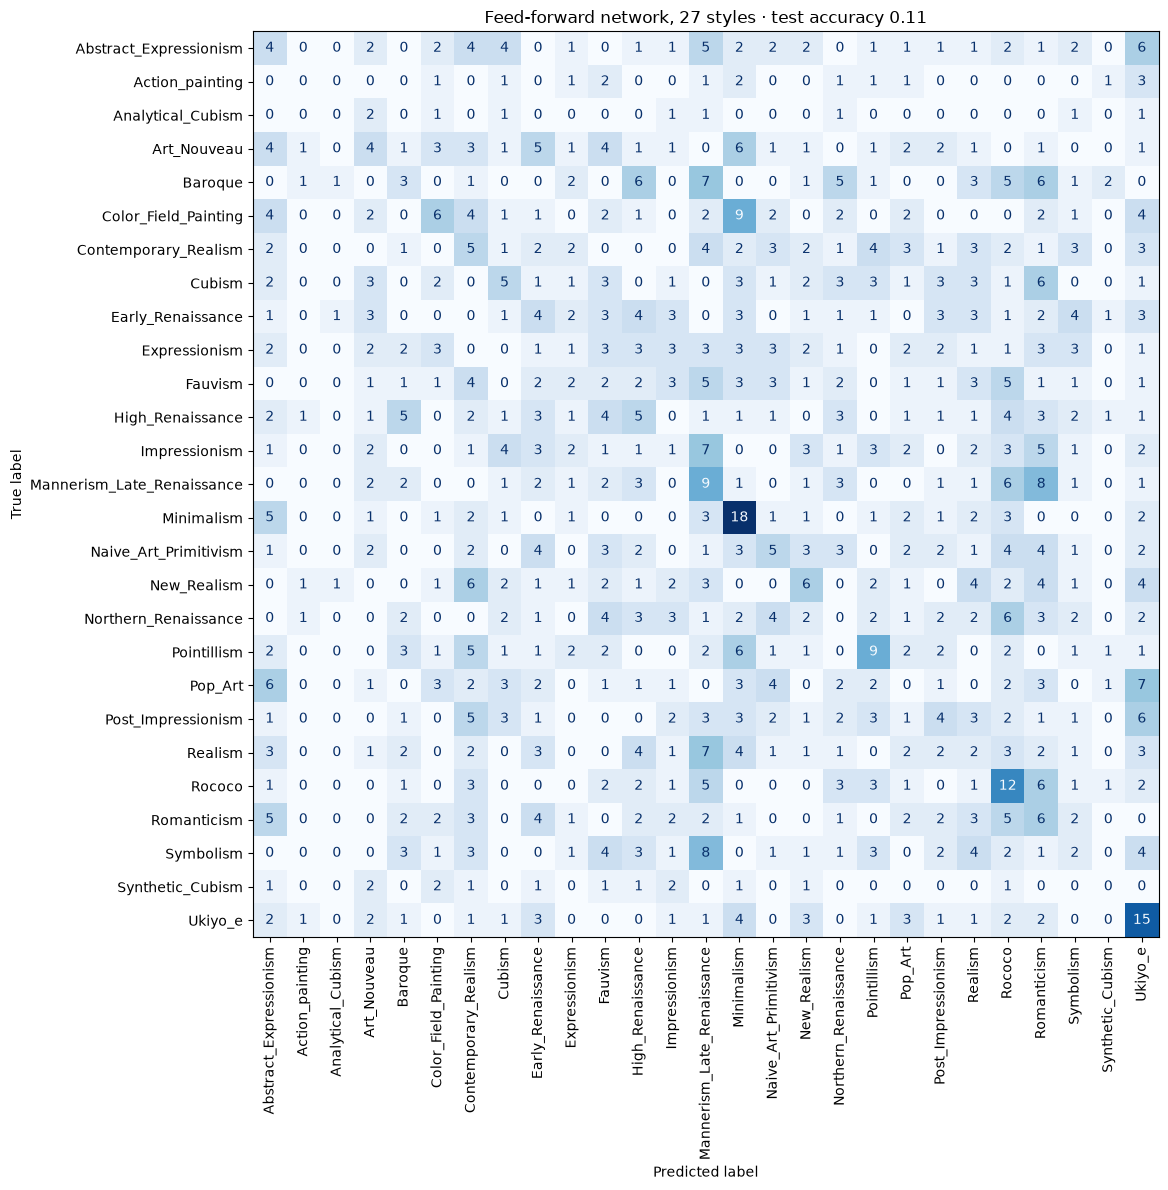

In [32]:
class_names = style["classes"]

# Entry [i, j] = number of test images of true class i predicted as class j (TP05, exercise 7)
cm = confusion_matrix(y_true, y_pred, labels=range(n_classes))

fig, ax = plt.subplots(figsize=(14, 12))  # 27 classes: a large figure so that the numbers stay readable
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(
    ax=ax, xticks_rotation=90, colorbar=False, cmap="Blues"
)
ax.set_title(f"Feed-forward network, 27 styles · test accuracy {test_acc:.2f}")
fig.tight_layout()
fig.savefig(FIG_DIR / "mlp_style_confusion_test.png", dpi=150)  # saved for the slides
plt.show()

## Accuracy per style and most frequent error

In [33]:
# Accuracy of each style: correct predictions divided by the number of test images of that style
per_class = cm.diagonal() / cm.sum(axis=1)
for name, acc in sorted(zip(class_names, per_class), key=lambda pair: -pair[1]):  # best styles first
    print(f"  {name:28s} {acc:.2f}")

# Most frequent mistake: the largest entry outside the diagonal (TP05, exercise 7)
off_diagonal = cm.copy()
np.fill_diagonal(off_diagonal, 0)
i, j = np.unravel_index(off_diagonal.argmax(), off_diagonal.shape)
print(f"most frequent mistake: true '{class_names[i]}' predicted as '{class_names[j]}' ({off_diagonal[i, j]} times)")

  Minimalism                   0.40
  Ukiyo_e                      0.33
  Rococo                       0.27
  Mannerism_Late_Renaissance   0.20
  Pointillism                  0.20
  Color_Field_Painting         0.13
  New_Realism                  0.13
  Romanticism                  0.13
  Contemporary_Realism         0.11
  Cubism                       0.11
  High_Renaissance             0.11
  Naive_Art_Primitivism        0.11
  Abstract_Expressionism       0.09
  Art_Nouveau                  0.09
  Early_Renaissance            0.09
  Post_Impressionism           0.09
  Baroque                      0.07
  Fauvism                      0.04
  Realism                      0.04
  Symbolism                    0.04
  Expressionism                0.02
  Impressionism                0.02
  Action_painting              0.00
  Analytical_Cubism            0.00
  Northern_Renaissance         0.00
  Pop_Art                      0.00
  Synthetic_Cubism             0.00
most frequent mistake: true 